In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.notebook import trange, tqdm
import numpy as np
import matplotlib.pyplot as plt
import time

In [ ]:
# Data preparation
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler


# Define the column labels
column_names = [
    "B_vec", "L_vec", "time", "Force_z", "disp"
]


# Load the file
df = pd.read_csv(
    'Dataset_2D_short.txt',
    sep='\s+',           # Matches one or more spaces/tabs
    header=None,         # Tells Pandas the first row is NOT a header
    names=column_names,  # Applies your labels to the columns in order
    index_col=False      # Prevents Pandas from using the first column as an index
)


#df['log_Fz'] = np.log10(df['Force_z'])
#df['log_d'] = np.log10(df['disp'])
df['log_Fz'] = np.log10(np.abs(df['Force_z']))
df['log_d'] = np.log10(np.abs(df['disp']))



# Check the result
print(df.head())

print(list(df.columns))

<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:19: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_16968/707455264.py:19: SyntaxWarning: invalid escape sequence '\s'
  sep='\s+',           # Matches one or more spaces/tabs


   B_vec  L_vec     time       Force_z          disp     log_Fz      log_d
0    0.0   20.0  0.00000  2.773737e-22  2.420000e-14 -21.556935 -13.616185
1    0.0   20.0  0.00022  3.999433e-04  6.050000e-07  -3.398002  -6.218245
2    0.0   20.0  0.00044  7.296190e-03  2.420000e-06  -2.136904  -5.616185
3    0.0   20.0  0.00066  1.943286e-02  5.445000e-06  -1.711463  -5.264002
4    0.0   20.0  0.00088  3.461483e-02  9.680000e-06  -1.460738  -5.014125
['B_vec', 'L_vec', 'time', 'Force_z', 'disp', 'log_Fz', 'log_d']


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import torch
from torch.utils.data import DataLoader, TensorDataset

# --- 1. Raggruppa per configurazione (B, L) ---
# Ogni gruppo è una curva F-d intera
grouped = df.groupby(['B_vec', 'L_vec'])

# --- 2. Feature engineering per curva ---
# Invece di un punto alla volta, aggrega tutta la curva in feature discriminanti
curve_features = []

for (b_val, l_val), group in grouped:
    log_fz = group['log_Fz'].values
    log_d  = group['log_d'].values
    max_fz = np.max(log_fz)

    # Feature che catturano la FORMA della curva, non un singolo punto
    slope_loglog = np.polyfit(log_d, log_fz, 1)[0]  # pendenza log-log ~ esponente potenza
    k_values     = 10**log_fz / 10**log_d           # K = F/d in scala reale
    k_max        = np.max(k_values)
    k_mean       = np.mean(k_values)
    k_std        = np.std(k_values)
    fz_range     = log_fz.max() - log_fz.min()      # escursione dinamica della forza

    curve_features.append({
        'B_vec':        b_val,
        'L_vec':        l_val,
        'slope_loglog': slope_loglog,
        'log_K_max':    np.log10(k_max),
        'log_K_mean':   np.log10(k_mean),
        'log_K_std':    np.log10(k_std),
        'fz_range':     fz_range,
        'n_points':     len(group),
    })

df_curves = pd.DataFrame(curve_features)
print(f"Numero di configurazioni (B, L): {len(df_curves)}")
print(df_curves.head())

# ======================= SCELTA FAETURES ===================
x_feat = df_curves[['B_vec','log_K_mean']].values
y_feat = df_curves['L_vec'].values.reshape(-1, 1)


# ==================== SPLIT =============================
x_train, x_temp, y_train, y_temp = train_test_split(
    x_feat, y_feat, test_size=0.30, random_state=42
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=42
)

print(f"Train: {len(x_train)} curve | Val: {len(x_val)} | Test: {len(x_test)}")
print(f"Train dimension: {x_train.shape} curve | Val: {x_val.shape} | Test: {x_test.shape}")


Numero di configurazioni (B, L): 420
   B_vec  L_vec  slope_loglog  log_K_max  log_K_mean  log_K_std   fz_range  \
0    0.0   20.0      1.863616   3.560556    3.535002   2.655748  22.103169   
1    0.0   21.0      1.866129   3.621144    3.582208   2.707625  22.183861   
2    0.0   22.0      1.863458   3.681959    3.627474   2.762055  22.194834   
3    0.0   23.0      1.860150   3.739672    3.670990   2.818594  22.196863   
4    0.0   24.0      1.849481   3.795117    3.712873   2.876563  22.097616   

   n_points  
0       101  
1       101  
2       101  
3       101  
4       101  
Train: 294 curve | Val: 63 | Test: 63
Train dimension: (294, 2) curve | Val: (63, 2) | Test: (63, 2)


In [ ]:
# ==============================================================================
# CHECK DEL LEAKAGE: VERIFICA SOVRAPPOSIZIONE CONFIGURAZIONI (B, L)
# ==============================================================================
print("\n" + "═"*60)
print("             VERIFICA DI SICUREZZA LEAKAGE (B, L)             ")
print("═"*60)

# Trasformiamo le righe dei vari split in set di tuple (B, L)
# Nota: nello x_train hai preso solo ['B_vec', 'log_K_mean'],
# quindi per ricostruire la coppia geometrica reale leggiamo sia x che y.
tuples_train = set(zip(x_train[:, 0], y_train.flatten()))
tuples_val   = set(zip(x_val[:, 0], y_val.flatten()))
tuples_test  = set(zip(x_test[:, 0], y_test.flatten()))

print(f"▶ Curve uniche reali nel TRAIN : {len(tuples_train)}")
print(f"▶ Curve uniche reali nel VAL   : {len(tuples_val)}")
print(f"▶ Curve uniche reali nel TEST  : {len(tuples_test)}")
print("-" * 60)

# Calcolo delle intersezioni
overlap_train_val  = tuples_train.intersection(tuples_val)
overlap_train_test = tuples_train.intersection(tuples_test)
overlap_val_test   = tuples_val.intersection(tuples_test)

# Flag di controllo globale
leakage_rilevato = False

if len(overlap_train_val) > 0:
    print(f"❌ LEAKAGE TRAIN-VAL! {len(overlap_train_val)} combinazioni condivise:")
    print(f"   Coppie (B, L): {overlap_train_val}")
    leakage_rilevato = True
else:
    print("✅ OK: Nessuna curva condivisa tra Train e Validation.")

if len(overlap_train_test) > 0:
    print(f"❌ LEAKAGE TRAIN-TEST! {len(overlap_train_test)} combinazioni condivise:")
    print(f"   Coppie (B, L): {overlap_train_test}")
    leakage_rilevato = True
else:
    print("✅ OK: Nessuna curva condivisa tra Train e Test.")

if len(overlap_val_test) > 0:
    print(f"❌ LEAKAGE VAL-TEST! {len(overlap_val_test)} combinazioni condivise:")
    print(f"   Coppie (B, L): {overlap_val_test}")
    leakage_rilevato = True
else:
    print("✅ OK: Nessuna curva condivisa tra Validation e Test.")

print("-" * 60)
if not leakage_rilevato:
    print("🎉 VERIFICA SUPERATA: Gli split sono reciprocamente esclusivi al 100%!")
else:
    print("⚠️ ATTENZIONE: Sistema i dati, c'è una contaminazione tra i set.")
print("═"*60)


════════════════════════════════════════════════════════════
             VERIFICA DI SICUREZZA LEAKAGE (B, L)             
════════════════════════════════════════════════════════════
▶ Curve uniche reali nel TRAIN : 294
▶ Curve uniche reali nel VAL   : 63
▶ Curve uniche reali nel TEST  : 63
------------------------------------------------------------
✅ OK: Nessuna curva condivisa tra Train e Validation.
✅ OK: Nessuna curva condivisa tra Train e Test.
✅ OK: Nessuna curva condivisa tra Validation e Test.
------------------------------------------------------------
🎉 VERIFICA SUPERATA: Gli split sono reciprocamente esclusivi al 100%!
════════════════════════════════════════════════════════════


In [ ]:
### NN 2 Hidden Layers

import torch
import torch.nn as nn

class MetaBeamMR_MLP(nn.Module):
    def __init__(self, n_input, n_output, n_hidden1,n_hidden2):
        super(MetaBeamMR_MLP, self).__init__()

        # Expanded capacity to prevent underfitting/clipping at boundaries
        self.inp = nn.Linear(n_input, n_hidden1)
        self.hid1 = nn.Linear(n_hidden1, n_hidden2)
        self.hid2 = nn.Linear(n_hidden2, n_hidden2)
        #self.hid3 = nn.Linear(n_hidden2, n_hidden2)
        #self.hid4 = nn.Linear(n_hidden2, n_hidden2)
        self.out = nn.Linear(n_hidden2, n_output)

        # Smooth activation function - excellent for physical continuous curves
        self.activation = nn.SiLU() # Alternatively, use nn.Tanh() or nn.ReLU()

    def forward(self, x):
        x = self.activation(self.inp(x))
        x = self.activation(self.hid1(x))
        x = self.activation(self.hid2(x))
        #x = self.activation(self.hid3(x))
        #x = self.activation(self.hid4(x))
        x = self.out(x)
        return x

In [ ]:
# ================
# NET DIM INPUT
# ==============

n_input = x_train.shape[1]
n_output = y_train.shape[1]
n_hidden1 = 8
n_hidden2 = 8
print(n_input, n_output)

2 1


In [ ]:
# ==============================================================================
#                      SCALING & PYTORCH CONVERSION
# ==============================================================================

scaler_x = StandardScaler()
#scaler_x = MinMaxScaler(feature_range=(0, 1))
#scaler_y = StandardScaler()
scaler_y = MinMaxScaler(feature_range=(0, 1))
#scaler_x = MinMaxScaler()
#scaler_y = MinMaxScaler()


# Fit and transform the Train set
x_train_scaled = scaler_x.fit_transform(x_train)
y_train_scaled = scaler_y.fit_transform(y_train)

# Transform only Validation and Test sets
x_val_scaled = scaler_x.transform(x_val)
y_val_scaled = scaler_y.transform(y_val)

x_test_scaled = scaler_x.transform(x_test)
y_test_scaled = scaler_y.transform(y_test)


# --- Convert to PyTorch Tensors (Using clear 't' suffix for clarity) ---
X_train_t = torch.tensor(x_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)

X_val_t   = torch.tensor(x_val_scaled, dtype=torch.float32)
y_val_t   = torch.tensor(y_val_scaled, dtype=torch.float32)

# ADD THIS: Creating the test tensors for your assessment function
X_test_t  = torch.tensor(x_test_scaled, dtype=torch.float32)
y_test_t  = torch.tensor(y_test_scaled, dtype=torch.float32)


# --- Create TensorDatasets ---
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset   = TensorDataset(X_val_t, y_val_t)
test_dataset  = TensorDataset(X_test_t, y_test_t)


# --- Create DataLoaders ---
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# ==============================================================================
# 1. DEFINIZIONE DELLA LOSS CUSTOM (PHYSICAL MAPE LOSS)
# ==============================================================================
class PhysicalMAPELoss(nn.Module):
    def __init__(self, scaler_y, eps=1e-6):
        super().__init__()
        self.eps = eps

        # Estraiamo i coefficienti dal MinMaxScaler(feature_range=(0, 1)) di scikit-learn
        # Formula MinMaxScaler: y_scaled = y * scale + min_  -->  y = (y_scaled - min_) / scale
        self.target_min = torch.tensor(scaler_y.min_[0], dtype=torch.float32)
        self.target_scale = torch.tensor(scaler_y.scale_[0], dtype=torch.float32)

    def forward(self, pred_scaled, target_scaled):
        # Spostamento automatico dei coefficienti sul device corrente dei tensori (CPU o GPU/CUDA)
        min_t = self.target_min.to(pred_scaled.device)
        scale_t = self.target_scale.to(pred_scaled.device)

        # Allineamento dimensionale per evitare problemi latenti di broadcasting
        target_scaled = target_scaled.view_as(pred_scaled)

        # 🌟 INVERSIONE LIVE DELLO SCALING: Riportiamo i tensori nei millimetri reali (L_vec)
        pred_mm = (pred_scaled - min_t) / scale_t
        target_mm = (target_scaled - min_t) / scale_t

        # Calcolo dell'errore relativo percentuale assoluto medio (MAPE)
        mape = torch.abs(pred_mm - target_mm) / (torch.abs(target_mm) + self.eps)
        return torch.mean(mape)

In [ ]:
"""
# ==============================================================================
# 2. ADDESTRAMENTO E CONFIGURAZIONE DEL TRAINING LOOP
# ==============================================================================

# --- Inizializzazione Modello ---
# (Assicurati che n_input rifletta il numero corretto di feature, es. 2 per log_K e B_vec)
model = MetaBeamMR_MLP(n_input, n_output, n_hidden1, n_hidden2)

# --- Configurazione Loss Fisico-Percentuale ---
# Passiamo lo scaler_y (MinMaxScaler) appena configurato nel tuo blocco precedente
criterion = PhysicalMAPELoss(scaler_y=scaler_y)

# --- Ottimizzatore ---
optimizer = optim.Adam(model.parameters(), lr=0.005)

# Liste per il monitoraggio storico delle performance
train_losses = []
val_losses = []

# Impostiamo le epoche (con la MAPE sono raccomandate più epoche per stabilizzare i gradienti)
epochs = 1500

print("═" * 65)
print("     AVVIO ADDESTRAMENTO MODELLO CON PHYSICAL MAPE LOSS (0-1)     ")
print("═" * 65)

for epoch in range(epochs):
    # --- FASE DI TRAINING ---
    model.train()
    running_train_loss = 0.0

    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()

        # Forward pass: l'output del modello esce nel range normalizzato [0, 1]
        predictions = model(batch_x)

        # Calcolo del gradiente basato sulla conversione interna in millimetri
        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer.step()

        # Accumulo pesato sulla dimensione del batch corrente
        running_train_loss += loss.item() * batch_x.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # --- FASE DI VALIDAZIONE ---
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch_x_v, batch_y_v in val_loader:
            v_predictions = model(batch_x_v)
            v_loss = criterion(v_predictions, batch_y_v)
            running_val_loss += v_loss.item() * batch_x_v.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    # Stampa i log a schermo (Moltiplichiamo per 100 per leggere direttamente il valore in % reale)
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:03d}/{epochs}] | Train MAPE: {epoch_train_loss*100:.2f}% | Val MAPE: {epoch_val_loss*100:.2f}%")

print("-" * 65)
print(" Addestramento Completato con Successo!")
print("═" * 65)
"""


'\n# ==============================================================================\n# 2. ADDESTRAMENTO E CONFIGURAZIONE DEL TRAINING LOOP\n# ==============================================================================\n\n# --- Inizializzazione Modello ---\n# (Assicurati che n_input rifletta il numero corretto di feature, es. 2 per log_K e B_vec)\nmodel = MetaBeamMR_MLP(n_input, n_output, n_hidden1, n_hidden2)\n\n# --- Configurazione Loss Fisico-Percentuale ---\n# Passiamo lo scaler_y (MinMaxScaler) appena configurato nel tuo blocco precedente\ncriterion = PhysicalMAPELoss(scaler_y=scaler_y)\n\n# --- Ottimizzatore ---\noptimizer = optim.Adam(model.parameters(), lr=0.005)\n\n# Liste per il monitoraggio storico delle performance\ntrain_losses = []\nval_losses = []\n\n# Impostiamo le epoche (con la MAPE sono raccomandate più epoche per stabilizzare i gradienti)\nepochs = 1500\n\nprint("═" * 65)\nprint("     AVVIO ADDESTRAMENTO MODELLO CON PHYSICAL MAPE LOSS (0-1)     ")\nprint("═" * 65)

In [ ]:

# =====================================================
#            TRAINING
# ======================================================


# --- Inizializzazione Modello, Ottimizzatore e Loss ---
model = MetaBeamMR_MLP(n_input, n_output, n_hidden1, n_hidden2)
criterion = nn.MSELoss()
#optimizer = optim.Adam(model.parameters(), lr=0.005)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

# Liste per salvare l'andamento delle loss
train_losses = []
val_losses = []

epochs = 100

print("═" * 50)
print("             AVVIO ADDESTRAMENTO MODELLO              ")
print("═" * 50)

for epoch in range(epochs):
    # --- FASE DI TRAINING ---
    model.train()
    running_train_loss = 0.0

    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        predictions = model(batch_x)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * batch_x.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # --- FASE DI VALIDAZIONE ---
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch_x_v, batch_y_v in val_loader:
            v_predictions = model(batch_x_v)
            v_loss = criterion(v_predictions, batch_y_v)
            running_val_loss += v_loss.item() * batch_x_v.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    # Stampa l'avanzamento ogni 10 epoche
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {epoch_train_loss:.5f} | Val Loss: {epoch_val_loss:.5f}")

print("-" * 50)
print(" Addestramento Completato!")
print("═" * 50)



══════════════════════════════════════════════════
             AVVIO ADDESTRAMENTO MODELLO              
══════════════════════════════════════════════════
Epoch [1/100] | Train Loss: 0.47099 | Val Loss: 0.41877
Epoch [10/100] | Train Loss: 0.00231 | Val Loss: 0.00262
Epoch [20/100] | Train Loss: 0.00065 | Val Loss: 0.00065
Epoch [30/100] | Train Loss: 0.00014 | Val Loss: 0.00013
Epoch [40/100] | Train Loss: 0.00005 | Val Loss: 0.00004
Epoch [50/100] | Train Loss: 0.00004 | Val Loss: 0.00003
Epoch [60/100] | Train Loss: 0.00004 | Val Loss: 0.00003
Epoch [70/100] | Train Loss: 0.00003 | Val Loss: 0.00003
Epoch [80/100] | Train Loss: 0.00003 | Val Loss: 0.00003
Epoch [90/100] | Train Loss: 0.00003 | Val Loss: 0.00003
Epoch [100/100] | Train Loss: 0.00003 | Val Loss: 0.00003
--------------------------------------------------
 Addestramento Completato!
══════════════════════════════════════════════════


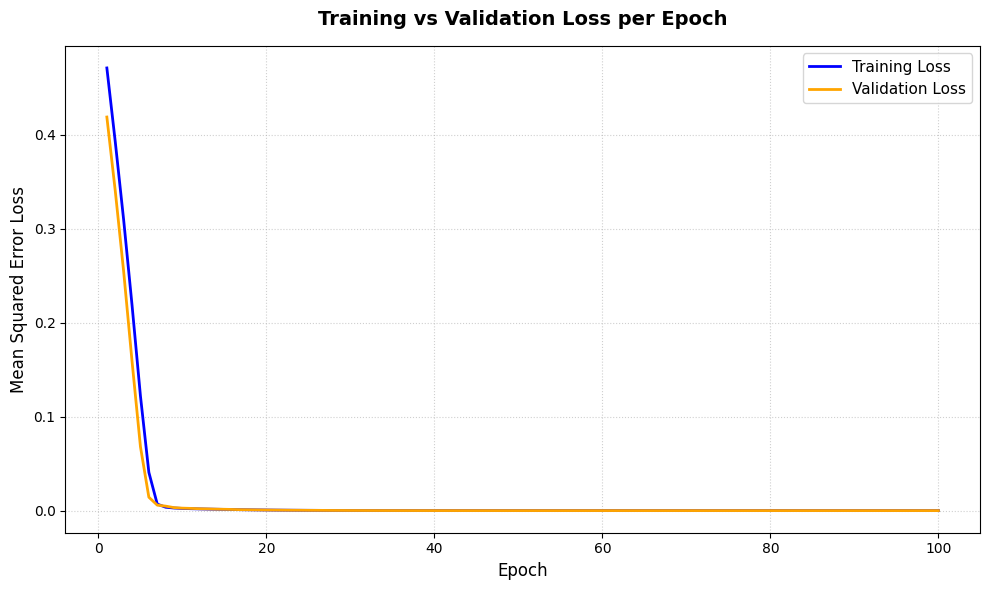

In [ ]:
# --- Generazione del Grafico delle Loss ---
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), train_losses, label='Training Loss', color='blue', linewidth=2)
plt.plot(range(1, epochs + 1), val_losses, label='Validation Loss', color='orange', linewidth=2)

plt.title('Training vs Validation Loss per Epoch', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Mean Squared Error Loss', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import torch
import matplotlib.pyplot as plt

def assess_results_v2(model, X, y, data_type):
    model.eval()
    with torch.no_grad():
        y_hat = model(X)

        # Convert tensors to 1D numpy arrays for clean plotting
        y_hat_np = y_hat.numpy().flatten()
        y_np = y.numpy().flatten()

        # 1. Initialize a clean, square figure
        plt.figure(figsize=(4, 4))

        # 2. Plot True Output on X-axis and Predicted Output on Y-axis
        plt.scatter(y_np, y_hat_np, alpha=0.6, color='#1f77b4', edgecolors='none', label='Predictions')

        # 3. Dynamic scale bounds to guarantee a perfectly square diagonal reference window
        min_val = min(y_np.min(), y_hat_np.min()) - 0.2
        max_val = max(y_np.max(), y_hat_np.max()) + 0.2
        plt.xlim(min_val, max_val)
        plt.ylim(min_val, max_val)

        # 4. Add the red dashed diagonal line (Ideal Fit)
        plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=1.5, label='Ideal Fit (y=x)')

        # 5. Add a subtle grid
        plt.grid(True, linestyle=':', alpha=0.6, color='gray')

        # 6. Labels and Title formatting
        plt.xlabel('True Output', fontsize=10)
        plt.ylabel('Predicted Output', fontsize=10)
        plt.title(f'R² Parity Plot: {data_type.capitalize()} Dataset', fontsize=11, fontweight='bold', pad=10)

        # 7. Add the legend with correct background transparency configuration
        plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none', framealpha=0.8)

        plt.tight_layout()
        plt.show()

        # RMSE calculation
        mse = torch.mean((y_hat - y) ** 2)
        rmse = torch.sqrt(mse)

        # R2 calculation
        total_variance = torch.var(y)
        R2 = 1 - (mse / total_variance)

    # Return items as standard python scalars for cleaner print outputs
    return rmse.item(), R2.item()


══════════════════════════════════════════════════
             EVALUATING MODEL PERFORMANCE             
══════════════════════════════════════════════════


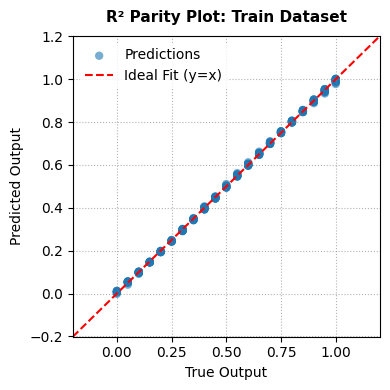

Training results:
  RMSE = 0.0052
  R²   = 1.000



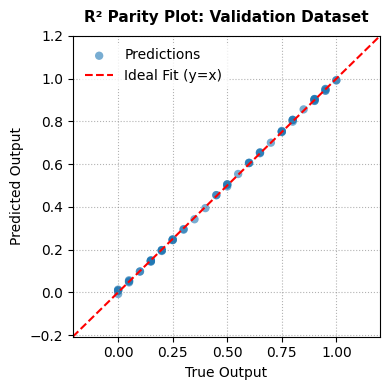

Validation results:
  RMSE = 0.0051
  R²   = 1.000



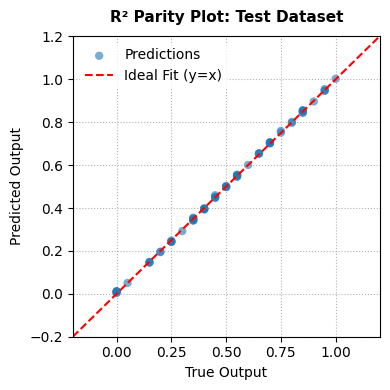

Test results:
  RMSE = 0.0052
  R²   = 1.000

══════════════════════════════════════════════════


In [ ]:
# ==============================================================================
# MODEL PERFORMANCE EVALUATION
# ==============================================================================
print("\n" + "═"*50)
print("             EVALUATING MODEL PERFORMANCE             ")
print("═" * 50)

# Assess results on the Training Set using PyTorch Tensors
rmse_train, R2_train = assess_results_v2(model, X_train_t, y_train_t, data_type='train')
print('Training results:')
print(f"  RMSE = {rmse_train:.4f}\n  R²   = {R2_train:.3f}\n")

# Assess results on the Validation Set using PyTorch Tensors
rmse_val, R2_val = assess_results_v2(model, X_val_t, y_val_t, data_type='validation')
print('Validation results:')
print(f"  RMSE = {rmse_val:.4f}\n  R²   = {R2_val:.3f}\n")

# Assess results on the final Test Set using PyTorch Tensors
rmse_test, R2_test = assess_results_v2(model, X_test_t, y_test_t, data_type='test')
print('Test results:')
print(f"  RMSE = {rmse_test:.4f}\n  R²   = {R2_test:.3f}\n")
print("═"*50)

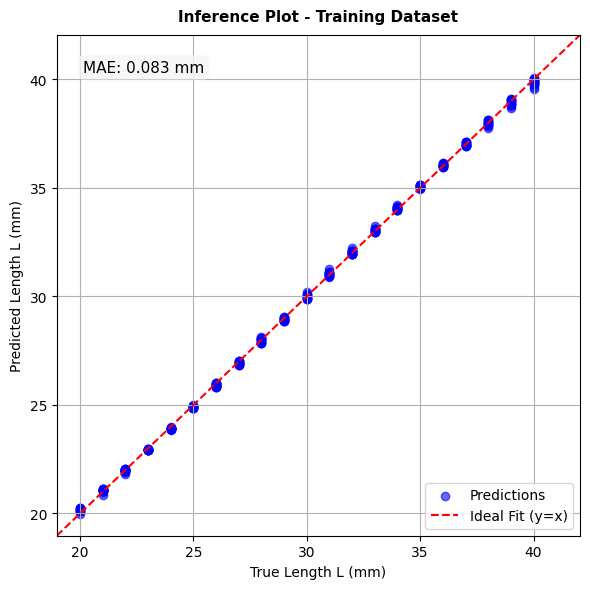

Training Dataset Summary -> R²: 0.9997 | MAE: 0.083 mm


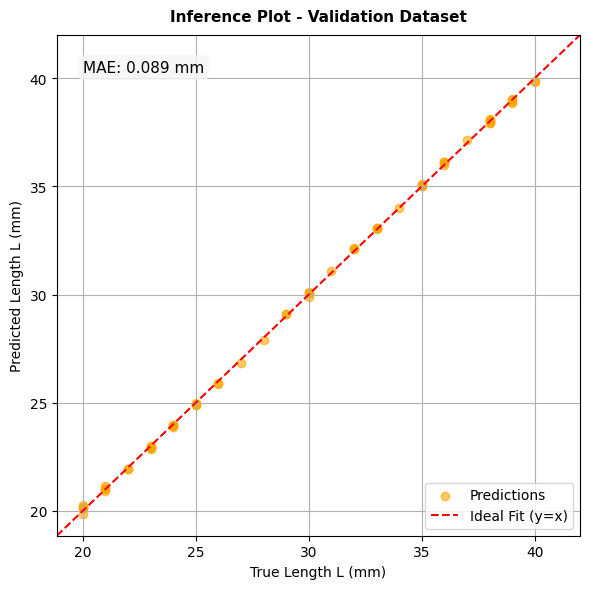

Validation Dataset Summary -> R²: 0.9998 | MAE: 0.089 mm


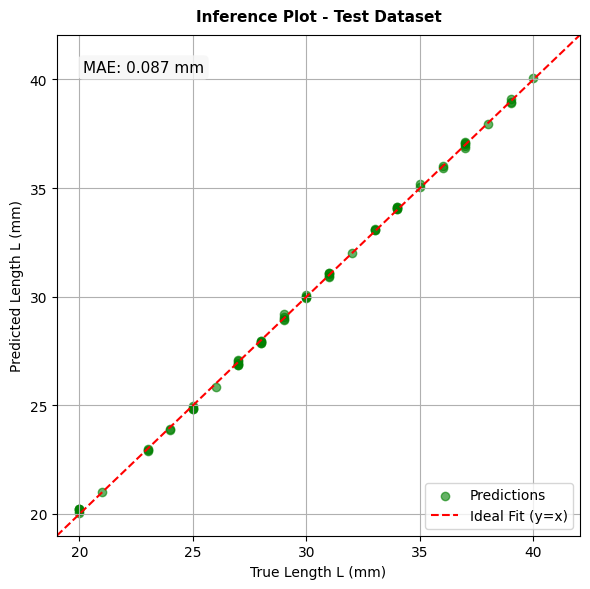

Test Dataset Summary -> R²: 0.9996 | MAE: 0.087 mm


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error
import torch

# --- 1. Generate Predictions (Scaled Space) ---
model.eval()
with torch.no_grad():
    pred_train_scaled = model(torch.tensor(x_train_scaled, dtype=torch.float32)).numpy()
    pred_val_scaled   = model(torch.tensor(x_val_scaled, dtype=torch.float32)).numpy()
    pred_test_scaled  = model(torch.tensor(x_test_scaled, dtype=torch.float32)).numpy()

# --- 2. Inverse Transform back to real-world units (mm) ---
y_train_pred = scaler_y.inverse_transform(pred_train_scaled).flatten()
y_val_pred   = scaler_y.inverse_transform(pred_val_scaled).flatten()
y_test_pred  = scaler_y.inverse_transform(pred_test_scaled).flatten()

# Extract real unscaled targets
y_train_true = y_train.flatten()
y_val_true   = y_val.flatten()
y_test_true  = y_test.flatten()

# --- 3. Individual Plot Definitions ---
splits_data = [
    ('Training', y_train_true, y_train_pred, 'blue'),
    ('Validation', y_val_true, y_val_pred, 'orange'),
    ('Test', y_test_true, y_test_pred, 'green')
]

for name, y_true, y_pred, point_color in splits_data:
    # Calculate evaluation metrics
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    # 1. Initialize standalone figure
    plt.figure(figsize=(6, 6))  # Kept square to maintain the 1:1 visual aspect ratio

    # 2. Scatter actual vs predicted coordinates
    plt.scatter(y_true, y_pred, alpha=0.6, color=point_color, label='Predictions')

    # 3. Calculate perfectly square scale limits for the diagonal identity line
    min_val = min(y_true.min(), y_pred.min()) * 0.95
    max_val = max(y_true.max(), y_pred.max()) * 1.05

    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)

    # 4. Draw the Ideal Fit diagonal baseline
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Ideal Fit (y=x)')

    # 5. Text Metric Overlay Box
    text_box = f'MAE: {mae:.3f} mm'
    props = dict(boxstyle='round', facecolor='whitesmoke', alpha=0.8, edgecolor='none')
    plt.gca().text(0.05, 0.95, text_box, transform=plt.gca().transAxes, fontsize=11,
                   verticalalignment='top', bbox=props)

    # 6. Labels and Minimalist Styling
    plt.title(f'Inference Plot - {name} Dataset', fontsize=11, fontweight='bold', pad=10)
    plt.xlabel('True Length L (mm)')
    plt.ylabel('Predicted Length L (mm)')
    plt.legend(loc='lower right')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    # Console tracking validation summary
    print(f"{name} Dataset Summary -> R²: {r2:.4f} | MAE: {mae:.3f} mm")

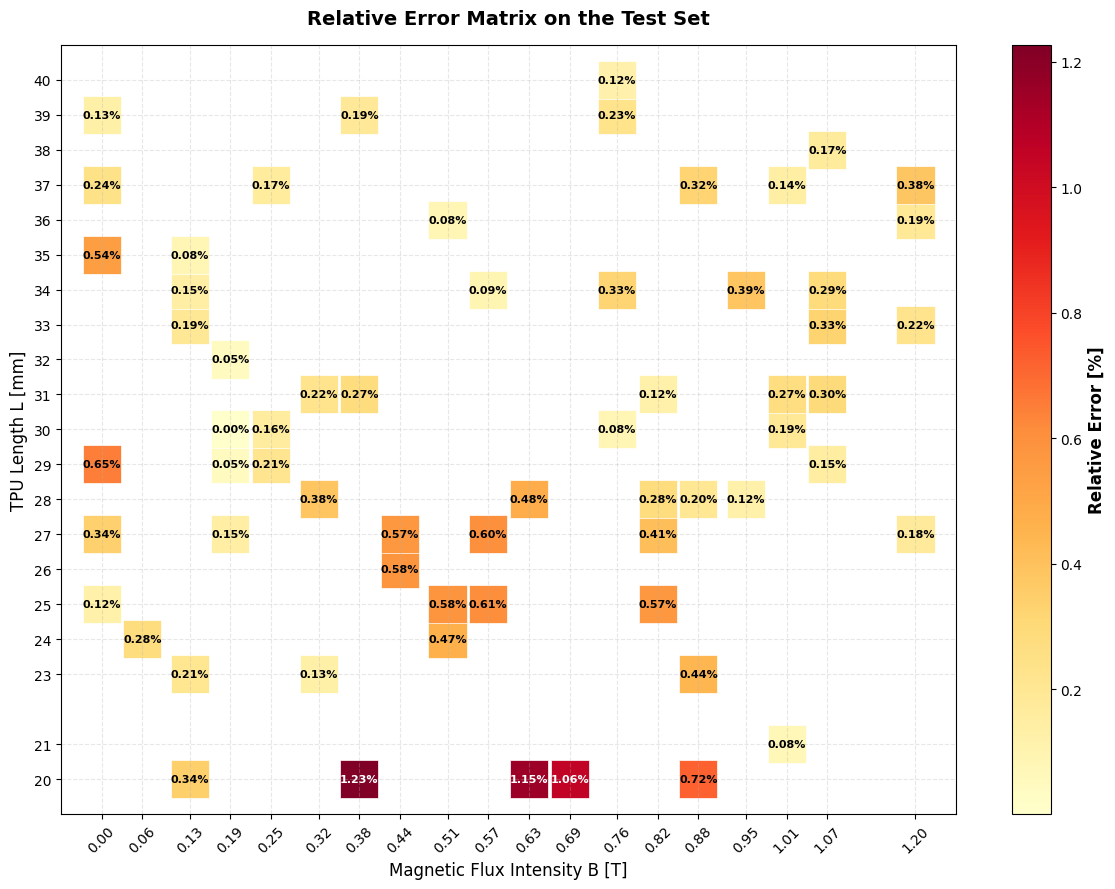

In [ ]:
# ==============================================================================
#  MAPPA SPARSA DELL'ERRORE RELATIVO PERCENTUALE (%) SUL TEST SET
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Recuperiamo B_vec direttamente da x_test (la colonna 0 è B_vec)
b_test_real = x_test[:, 0]

# 2. Creazione del DataFrame dei residui percentuali
df_res_test = pd.DataFrame({
    'B_vec': b_test_real,
    'L_vec': y_test_true,
    'L_pred': y_test_pred
})

# Calcolo dell'errore relativo percentuale
df_res_test['Relative_Error_Percent'] = (np.abs(df_res_test['L_vec'] - df_res_test['L_pred']) / df_res_test['L_vec']) * 100

# Arrotondamento per pulizia
df_res_test['L_vec'] = df_res_test['L_vec'].round(1)
df_res_test['B_vec'] = df_res_test['B_vec'].round(2)

# Raggruppiamo i dati duplicati calcolandone la media per evitare sovrapposizioni nello scatter
df_grouped = df_res_test.groupby(['B_vec', 'L_vec'], as_index=False)['Relative_Error_Percent'].mean()

# 3. Generazione del Grafico tramite Scatter Plot a Matrice
plt.figure(figsize=(12, 9))

# Creiamo lo scatter colorato in base all'errore
sc = plt.scatter(
    df_grouped['B_vec'],
    df_grouped['L_vec'],
    c=df_grouped['Relative_Error_Percent'],
    cmap='YlOrRd',
    marker='s',        # Usa quadrati simili alla heatmap
    s=750,             # Dimensione del blocco quadrato
    edgecolors='white',
    linewidths=0.5
)

# Aggiungiamo il testo dell'errore al centro di ogni quadrato
for idx, row in df_grouped.iterrows():
    plt.text(
        row['B_vec'],
        row['L_vec'],
        f"{row['Relative_Error_Percent']:.2f}%",
        color='black' if row['Relative_Error_Percent'] < 0.8 else 'white', # Contrasto automatico
        ha='center',
        va='center',
        fontweight='bold',
        fontsize=8
    )

# Configurazione Assi e Campionamento Etichette
plt.xticks(np.sort(df_grouped['B_vec'].unique()), rotation=45)
plt.yticks(np.sort(df_grouped['L_vec'].unique()))

# Barra del colore a destra
cbar = plt.colorbar(sc)
cbar.set_label('Relative Error [%]', fontsize=12, fontweight='bold')

plt.title('Relative Error Matrix on the Test Set', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Magnetic Flux Intensity B [T]', fontsize=12)
plt.ylabel('TPU Length L [mm]', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

import numpy as np
import pandas as pd
import torch

# ==============================================================================
# 1. NEW DATA LOADING & CONVERSIONS
# ==============================================================================
column_names = ["B_vec", "L_vec", "time", "disp", "force"]
dg = pd.read_csv(
    'Inference_data_v4.txt',
    sep=r'\s+',
    header=None,
    names=column_names,
    comment='%',
    index_col=False
)

# Use absolute magnitudes to handle any directional coordinate signs,
# exactly matching the baseline file loading parameters
dg['disp'] = np.abs(dg['disp'])
dg['force'] = np.abs(dg['force'])

# --- 🔄 PARAMETER-BASED SLICING ---
# Automatically identifies curves whenever B_vec or L_vec steps change
condition_new_curve = (dg['B_vec'].diff() != 0) | (dg['L_vec'].diff() != 0)
start_indices = dg[condition_new_curve].index.tolist()
n_curve_rilevate = len(start_indices)

print(f"🔄 Rilevate {n_curve_rilevate} curve distinte nel file di inferenza.")

# ==============================================================================
# 2. FEATURE ENGINEERING MATCHED TO TRAINING MATHEMATICS
# ==============================================================================
inference_features = []

for idx in range(n_curve_rilevate):
    idx_inizio = start_indices[idx]
    idx_fine = start_indices[idx + 1] if idx + 1 < n_curve_rilevate else len(dg)
    curva_comsol = dg.iloc[idx_inizio:idx_fine]

    actual_b = curva_comsol['B_vec'].iloc[0]
    actual_l = curva_comsol['L_vec'].iloc[0]

    # Grab the raw absolute values directly, matching the training logic
    disp_reale = curva_comsol['disp'].values
    force_reale = curva_comsol['force'].values

    # Clean out exact zero values to safely prevent division by zero errors
    mask = (disp_reale > 1e-9) & (force_reale > 0)
    disp_reale = disp_reale[mask]
    force_reale = force_reale[mask]

    if len(disp_reale) == 0:
        continue

    # Calculate absolute instantaneous stiffness (K = F/d), identical to training
    k_values = force_reale / disp_reale
    k_values = k_values[np.isfinite(k_values)]

    k_mean = np.mean(k_values)

    # Append features using the identical mapping structure used during model training
    inference_features.append({
        'B_vec': actual_b,
        'L_vec': actual_l,
        'log_K_mean': np.log10(k_mean)  # Pure log10, matching your training code
    })

dg_raw = pd.DataFrame(inference_features)


# ==============================================================================
# 3. PREDICTION PIPELINE
# ==============================================================================
# Extract exactly the 2 columns expected by your scaler: ['B_vec', 'log_K_mean']
x_new = dg_raw[['B_vec', 'log_K_mean']].values
y_new_true = dg_raw['L_vec'].values.reshape(-1, 1)

# Pass features through your trained scaler
x_new_scaled = scaler_x.transform(x_new)

# Generate predictions using your PyTorch model
model.eval()
with torch.no_grad():
    tensor_x_new = torch.tensor(x_new_scaled, dtype=torch.float32)
    pred_new_scaled = model(tensor_x_new).numpy()

# Inverse transform predictions back to real millimeter units
y_new_pred = scaler_y.inverse_transform(pred_new_scaled).flatten()
y_new_true = y_new_true.flatten()

# Save final assessment dataframe
df_inference_results = pd.DataFrame({
    'B_vec': dg_raw['B_vec'],
    'L_vec_reale': y_new_true,
    'L_vec_predetto': y_new_pred,
    'Errore_Assoluto_mm': np.abs(y_new_true - y_new_pred)
})

print("\n--- CARATTERISTICHE ESTRATTE ED ERRORE DI INFERENZA ---")
print(df_inference_results)

"""
# ==============================================================================
# 3. PREDICTION PIPELINE + PHYSICS-INFORMED POST-CORRECTION
# ==============================================================================
# Extract exactly the 2 columns expected by your scaler: ['B_vec', 'log_K_mean']
x_new = dg_raw[['B_vec', 'log_K_mean']].values
y_new_true = dg_raw['L_vec'].values.reshape(-1, 1)

# Pass features through your trained scaler
x_new_scaled = scaler_x.transform(x_new)

# Generate baseline predictions using your PyTorch model
model.eval()
with torch.no_grad():
    tensor_x_new = torch.tensor(x_new_scaled, dtype=torch.float32)
    pred_new_scaled = model(tensor_x_new).numpy()

# Inverse transform predictions back to real millimeter units
# 🌟 STEP 1: Questa è la tua L_collapsed (vettore di tutte le predizioni piatte del modello)
y_new_pred_collapsed = scaler_y.inverse_transform(pred_new_scaled).flatten()
y_new_true = y_new_true.flatten()


# 🌟 STEP 2: Estraiamo la rigidezza fisica reale (unlogged) per TUTTE le curve contemporaneamente
# Corrisponde al tuo: K_actual = 10**(log_K_mean)
k_actual = 10 ** (dg_raw['log_K_mean'].values)


# 🌟 STEP 3: Calcoliamo il punto di ancoraggio fisso basato sulla riga inferiore (L = 21.3 mm)
# Corrisponde al tuo: K_reference, usando i dati di inferenza disponibili
log_K_reference = dg_raw[dg_raw['L_vec'] == 21.3]['log_K_mean'].mean()

# Controllo di sicurezza: se L=21.3 non è presente nell'inferenza corrente, prende il valore minimo di L
if np.isnan(log_K_reference):
    log_K_reference = dg_raw[dg_raw['L_vec'] == dg_raw['L_vec'].min()]['log_K_mean'].mean()

k_reference = 10 ** log_K_reference


# 🌟 STEP 4: Applichiamo la legge della radice cubica invertita (Eulero-Bernoulli) su tutto il vettore
# Corrisponde esattamente al tuo: L_corrected = L_collapsed * (K_reference / K_actual) ** (1/3)
y_new_pred_corrected = y_new_pred_collapsed * (k_reference / k_actual) ** (1/3)



# ==============================================================================
# SALVATAGGIO DEI RISULTATI FINALI CORRETTI
# ==============================================================================
df_inference_results = pd.DataFrame({
    'B_vec': dg_raw['B_vec'],
    'L_vec_reale': y_new_true,
    #'L_vec_collassato_MLP': y_new_pred_collapsed,  # Il valore piatto originale (~21.5 mm)
    'L_vec_predetto': y_new_pred_corrected,        # La lunghezza corretta analiticamente dalla fisica
    'Errore_Assoluto_mm': np.abs(y_new_true - y_new_pred_corrected)
})

# Ricalcoliamo l'errore percentuale sulla nuova predizione fisica
df_inference_results['Errore_Relativo_Percent'] = (
    df_inference_results['Errore_Assoluto_mm'] / df_inference_results['L_vec_reale']
) * 100


print("\n--- CARATTERISTICHE ESTRATTE ED ERRORE DI INFERENZA CORRETTO DALLA FISICA ---")
print(df_inference_results.to_string(index=False))
"""

🔄 Rilevate 147 curve distinte nel file di inferenza.

--- CARATTERISTICHE ESTRATTE ED ERRORE DI INFERENZA ---
     B_vec  L_vec_reale  L_vec_predetto  Errore_Assoluto_mm
0      0.0         20.0       19.929981            0.070019
1      0.0         21.0       19.857584            1.142416
2      0.0         22.0       19.783028            2.216972
3      0.0         23.0       19.707823            3.292177
4      0.0         24.0       19.632812            4.367188
..     ...          ...             ...                 ...
142    1.2         36.0       16.926598           19.073402
143    1.2         37.0       16.801958           20.198042
144    1.2         38.0       16.682098           21.317902
145    1.2         39.0       16.567461           22.432539
146    1.2         40.0       16.456240           23.543760

[147 rows x 4 columns]


'\n# ==============================================================================\n# 3. PREDICTION PIPELINE + PHYSICS-INFORMED POST-CORRECTION\n# ==============================================================================\n# Extract exactly the 2 columns expected by your scaler: [\'B_vec\', \'log_K_mean\']\nx_new = dg_raw[[\'B_vec\', \'log_K_mean\']].values\ny_new_true = dg_raw[\'L_vec\'].values.reshape(-1, 1)\n\n# Pass features through your trained scaler\nx_new_scaled = scaler_x.transform(x_new)\n\n# Generate baseline predictions using your PyTorch model\nmodel.eval()\nwith torch.no_grad():\n    tensor_x_new = torch.tensor(x_new_scaled, dtype=torch.float32)\n    pred_new_scaled = model(tensor_x_new).numpy()\n\n# Inverse transform predictions back to real millimeter units\n# 🌟 STEP 1: Questa è la tua L_collapsed (vettore di tutte le predizioni piatte del modello)\ny_new_pred_collapsed = scaler_y.inverse_transform(pred_new_scaled).flatten()\ny_new_true = y_new_true.flatten()\n\n\n

In [ ]:
# ==============================================================================
#  INFERENZA SUI NUOVI DATI E CALCOLO DELL'ERRORE PER OGNI COPPIA (B, L)
# ==============================================================================

# ================== SCELTA FEATURE INFERENZA =====================
x_new = dg_raw[['B_vec', 'log_K_mean']].values
y_new_true = dg_raw['L_vec'].values.reshape(-1, 1)

# --- TRASFORMAZIONE CON GLI SCALER DEL TRAINING (IMPORTANTE!) ---
# Usiamo .transform() e NON .fit_transform() per mantenere la calibrazione del Train
x_new_scaled = scaler_x.transform(x_new)

# --- PASSAGGIO NEL MODELLO (PREDIZIONE) ---
model.eval()
with torch.no_grad():
    tensor_x_new = torch.tensor(x_new_scaled, dtype=torch.float32)
    pred_new_scaled = model(tensor_x_new).numpy()

# --- INVERSE TRANSFORM DELLE PREDIZIONI ---
# Riportiamo L da valori scalati a millimetri reali
y_new_pred = scaler_y.inverse_transform(pred_new_scaled).flatten()
y_new_true = y_new_true.flatten()

# --- CREAZIONE DEL DATAFRAME DEI RISULTATI ---
df_inference_results = pd.DataFrame({
    'B_vec': dg_raw['B_vec'],
    'L_vec_reale': y_new_true,
    'L_vec_predetto': y_new_pred
})


═══════════════════════════════════════════════════════════════════════════
             RISULTATI COMPLETI DELL'INFERENZA (COMSOL)             
═══════════════════════════════════════════════════════════════════════════
B_vec L_vec_reale L_vec_predetto Errore_Relativo_Percent
 0.00        20.0         19.930                   0.35%
 0.00        21.0         19.858                   5.44%
 0.00        22.0         19.783                  10.08%
 0.00        23.0         19.708                  14.31%
 0.00        24.0         19.633                  18.20%
 0.00        25.0         19.559                  21.76%
 0.00        26.0         19.486                  25.05%
 0.00        27.0         19.415                  28.09%
 0.00        28.0         19.344                  30.92%
 0.00        29.0         19.272                  33.54%
 0.00        30.0         19.202                  35.99%
 0.00        31.0         19.134                  38.28%
 0.00        32.0         19.070     

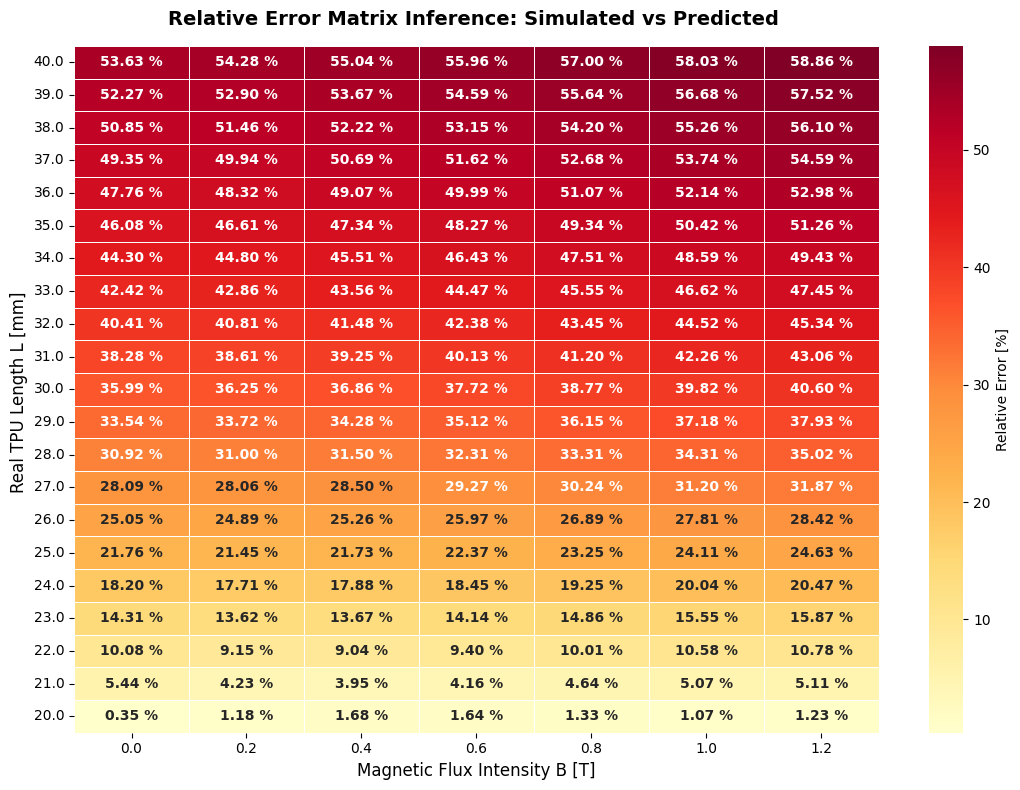

In [ ]:
# Calcolo dell'Errore Relativo Percentuale (%)
df_inference_results['Errore_Relativo_Percent'] = (
    np.abs(df_inference_results['L_vec_reale'] - df_inference_results['L_vec_predetto'])
    / df_inference_results['L_vec_reale']
) * 100

print("\n" + "═"*75)
print("             RISULTATI COMPLETI DELL'INFERENZA (COMSOL)             ")
print("═"*75)
print(df_inference_results.to_string(index=False, formatters={
    'B_vec': '{:.2f}'.format, 'L_vec_reale': '{:.1f}'.format,
    'L_vec_predetto': '{:.3f}'.format, 'Errore_Relativo_Percent': '{:.2f}%'.format
}))
print("═"*75)

"""
# --- 5. VISUALIZZAZIONE GRAFICA (HEATMAP DELL'ERRORE DI INFERENZA) ---
import seaborn as sns

# Creiamo la matrice pivot per la mappa 2D
inference_error_matrix = df_inference_results.pivot_table(
    index='L_vec_reale',
    columns='B_vec',
    values='Errore_Relativo_Percent',
    aggfunc='mean'
).sort_index(ascending=False)

plt.figure(figsize=(11, 8))
sns.heatmap(
    inference_error_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={'label': 'Errore Relativo Medio (%)'},
    annot_kws={"size": 10, "weight": "bold"}
)

# Aggiungiamo il simbolo '%' a schermo per chiarezza visiva
for text in plt.gca().texts:
    text.set_text(text.get_text() + " %")

plt.title('Mappa dell\'Errore Relativo Percentuale (%) sui Nuovi Dati di Inferenza', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Parametro Geometrico B (B_vec)', fontsize=12)
plt.ylabel('Lunghezza Strutturale L Reale (L_vec - mm)', fontsize=12)
plt.tight_layout
plt.show()
"""

# ==============================================================================
# 5. VISUALIZZAZIONE GRAFICA (HEATMAP DELL'ERRORE DI INFERENZA)
# ==============================================================================
import seaborn as sns
import matplotlib.pyplot as plt

# 🌟 FIX 1: Arrotondamento preventivo a 1 cifra decimale per eliminare gli artefatti del floating-point
df_inference_results['L_vec_reale'] = df_inference_results['L_vec_reale'].round(1)
df_inference_results['B_vec'] = df_inference_results['B_vec'].round(1)

# Creiamo la matrice pivot per la mappa 2D
inference_error_matrix = df_inference_results.pivot_table(
    index='L_vec_reale',
    columns='B_vec',
    values='Errore_Relativo_Percent',
    aggfunc='mean'
).sort_index(ascending=False)

plt.figure(figsize=(11, 8))
sns.heatmap(
    inference_error_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={'label': 'Relative Error [%]'},
    annot_kws={"size": 10, "weight": "bold"}
)

# Aggiungiamo il simbolo '%' a schermo per chiarezza visiva
for text in plt.gca().texts:
    text.set_text(text.get_text() + " %")

plt.title('Relative Error Matrix Inference: Simulated vs Predicted ', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Magnetic Flux Intensity B [T]', fontsize=12)
plt.ylabel('Real TPU Length L [mm] ', fontsize=12)

# 🌟 FIX 2: Aggiunte le parentesi tonde corrette per applicare il layout compatto ed evitare scritte tagliate
plt.tight_layout()

plt.show()